# Clasificación de calidad de vino (BUENA / MALA): EDA, selección de características y partición de datos

**Flujo del notebook** (el orden evita *data leakage*):

1. Carga y auditoría de datos
2. Variable objetivo (*feature engineering* sobre `quality`)
3. EDA: distribuciones, outliers, relación con el target, correlaciones
4. Partición estratificada train / val / test
5. Armar un par de variables nuevas y suavizar las que tienen cola larga
6. Elegir las 6 características que más se relacionan con la calidad
7. Estandarizar y guardar los datos para PyTorch

## 0. Configuración

In [83]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import kagglehub as kh

SEED = 42
DATA_PATH = kh.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")  # <-- cambie por la ruta de su archivo
THRESHOLD = 6                        # quality >= THRESHOLD  ->  BUENA (ver sección 2)
MAX_FEATURES = 6

np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Carga y auditoría de datos

In [84]:
from pathlib import Path

path = Path(DATA_PATH)
if path.is_dir():
    csv_files = sorted(path.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError(f"No se encontró ningún CSV dentro de: {path}")
    data_file = csv_files[0]
else:
    data_file = path

print("Archivo utilizado:", data_file)
df = pd.read_csv(data_file, sep=None, engine="python")
df.columns = [c.strip().strip('"') for c in df.columns]
print("Dimensiones:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype").T)

Archivo utilizado: /Users/danielmendez/.cache/kagglehub/datasets/uciml/red-wine-quality-cortez-et-al-2009/versions/2/winequality-red.csv
Dimensiones: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


### 1.1 Análisis preliminar del dataset (antes del EDA)

Chequeo rápido de **estructura, calidad y viabilidad** del conjunto. Responde: ¿qué tengo?, ¿está limpio?, ¿es coherente?,
¿alcanza para entrenar una regresión logística? Cada bloque imprime su propia interpretación.

### A. Estructura general 

In [85]:
n, p = df.shape
non_num = df.select_dtypes(exclude="number").columns.tolist()
print(f"Observaciones: {n} | Columnas: {p} | Memoria: {df.memory_usage(deep=True).sum()/1024:.1f} KB")
print("Columnas no numéricas:", non_num or "ninguna")

Observaciones: 1599 | Columnas: 12 | Memoria: 150.0 KB
Columnas no numéricas: ninguna


### B. Ficha por variable

In [86]:
num = df.select_dtypes(include="number")
ficha = pd.DataFrame({
    "dtype": df.dtypes.astype(str), "nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2),
    "únicos": df.nunique(), "ceros": (num == 0).sum(),
    "min": num.min(), "mediana": num.median(), "max": num.max(), "media": num.mean(), "std": num.std()})
display(ficha.round(3))

,dtype,nulos,% nulos,únicos,ceros,min,mediana,max,media,std
fixed acidity,float64,0,0.0,96,0,4.600,7.900,15.900,8.320,1.741
volatile acidity,float64,0,0.0,143,0,0.120,0.520,1.580,0.528,0.179
citric acid,float64,0,0.0,80,132,0.000,0.260,1.000,0.271,0.195
residual sugar,float64,0,0.0,91,0,0.900,2.200,15.500,2.539,1.410
chlorides,float64,0,0.0,153,0,0.012,0.079,0.611,0.087,0.047
free sulfur dioxide,float64,0,0.0,60,0,1.000,14.000,72.000,15.875,10.460
total sulfur dioxide,float64,0,0.0,144,0,6.000,38.000,289.000,46.468,32.895
density,float64,0,0.0,436,0,0.990,0.997,1.004,0.997,0.002
pH,float64,0,0.0,89,0,2.740,3.310,4.010,3.311,0.154
sulphates,float64,0,0.0,96,0,0.330,0.620,2.000,0.658,0.170


### C. Calidad de datos 


In [87]:
n_null, n_dup = int(df.isna().sum().sum()), int(df.duplicated().sum())
const = [c for c in num if num[c].nunique() <= 1]
discretas = [c for c in num if 1 < num[c].nunique() <= 10]
neg = [c for c in num if (num[c] < 0).any()]

print(f"Valores nulos: {n_null} | Filas duplicadas: {n_dup} | Columnas constantes: {const or 'ninguna'}")
print(f"Columnas discretas: {discretas or 'ninguna'} | Columnas con valores negativos: {neg or 'ninguna'}")

Valores nulos: 0 | Filas duplicadas: 240 | Columnas constantes: ninguna
Columnas discretas: ['quality'] | Columnas con valores negativos: ninguna


### D. Escalas y balance de clases (versión simple) 


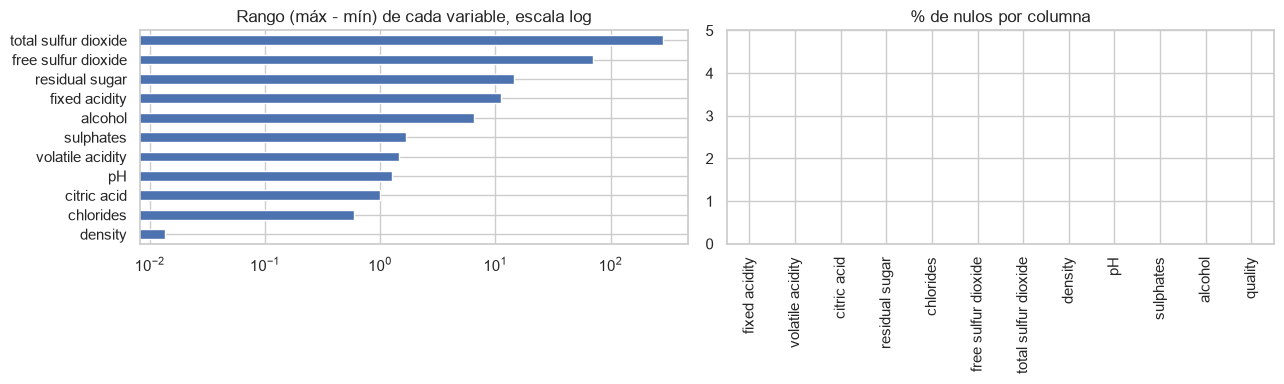

In [88]:
feats = num.drop(columns=[c for c in ["quality"] if c in num])
rangos = (feats.max() - feats.min())                  # cuánto varía cada variable
pct_buena = (df["quality"] >= THRESHOLD).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rangos.sort_values().plot.barh(ax=ax[0], logx=True, color="#4C72B0"); ax[0].set_title("Rango (máx - mín) de cada variable, escala log")
(df.isna().mean() * 100).plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("% de nulos por columna"); ax[1].set_ylim(0, 5)
plt.tight_layout(); plt.show()

### Interpretacion de resultados:

1) Tamaño: 1599 filas y 11 variables predictoras. Hay datos suficientes para un modelo sencillo.
2) Nulos: 0. No hace falta rellenar datos.
3) Duplicados: 240 (15.0%). Se eliminarán antes de dividir los datos.
4) Columnas constantes: ninguna (una columna con un solo valor no sirve para predecir).
5) Variables con pocos valores distintos: ['quality']. 'quality' es un puntaje entero, así que la convertiremos en BUENA/MALA.
6) Valores negativos: ninguno (no deberían existir en estas mediciones).
7) pH va de 2.74 a 4.01: valores razonables para un vino.
8) Escalas: 'total sulfur dioxide' varía en un rango de 283.0, mientras que 'density' solo en 0.014. Como son tan distintas, las pondremos en la misma escala (estandarizar) antes de entrenar.
9) Balance: 53% de los vinos son BUENA y 47% MALA (con umbral 6). Las clases están parecidas en tamaño.

## 2. Variable objetivo (feature engineering sobre `quality`)

`quality` es una puntuación ordinal (≈3 a 8). Para un problema binario hay que elegir un umbral. Se compara el balance de clases
para cada posible corte antes de decidir.

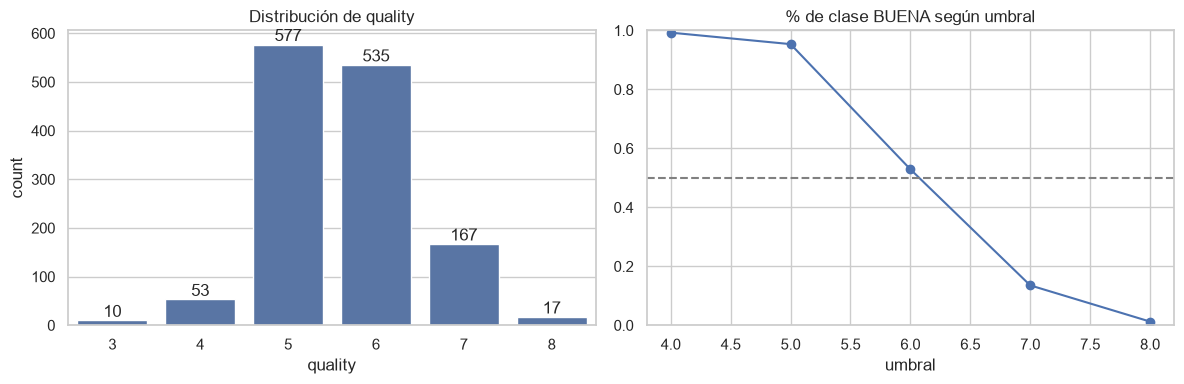

,umbral (>=),% BUENA,n BUENA,n MALA
0,4,0.993,1349,10
1,5,0.954,1296,63
2,6,0.529,719,640
3,7,0.135,184,1175
4,8,0.013,17,1342


In [91]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=df, ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribución de quality")
for v in ax[0].containers: ax[0].bar_label(v)

rows = [(t, (df.quality >= t).mean(), (df.quality >= t).sum(), (df.quality < t).sum()) for t in sorted(df.quality.unique())[1:]]
tab = pd.DataFrame(rows, columns=["umbral (>=)", "% BUENA", "n BUENA", "n MALA"])
ax[1].plot(tab["umbral (>=)"], tab["% BUENA"], "o-"); ax[1].axhline(0.5, ls="--", c="gray")
ax[1].set_title("% de clase BUENA según umbral"); ax[1].set_xlabel("umbral"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()
display(tab.round(3))

**Interpretación.** `quality` se concentra en pocos valores centrales (5 y 6), con colas muy delgadas. Un umbral de 6 produce clases
aproximadamente balanceadas; un umbral de 7 produce una clase positiva minoritaria (~10-15 %), lo que exigiría métricas como
F1/PR-AUC y *stratified sampling* de forma crítica.

> `quality` debe **excluirse** de las predictoras: el target se deriva directamente de ella (fuga de información).

In [92]:
df["target"] = (df["quality"] >= THRESHOLD).astype(int)   # 1 = BUENA, 0 = MALA
raw_features = [c for c in df.columns if c not in ("quality", "target")]
print("Predictoras candidatas:", raw_features)
print(df["target"].value_counts().rename({0: "MALA", 1: "BUENA"}))
print(f"Proporción BUENA: {df.target.mean():.3f}")

Predictoras candidatas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
target
BUENA    719
MALA     640
Name: count, dtype: int64
Proporción BUENA: 0.529


## 3. Análisis exploratorio

### 3.1 Distribuciones univariadas (histogramas + KDE)

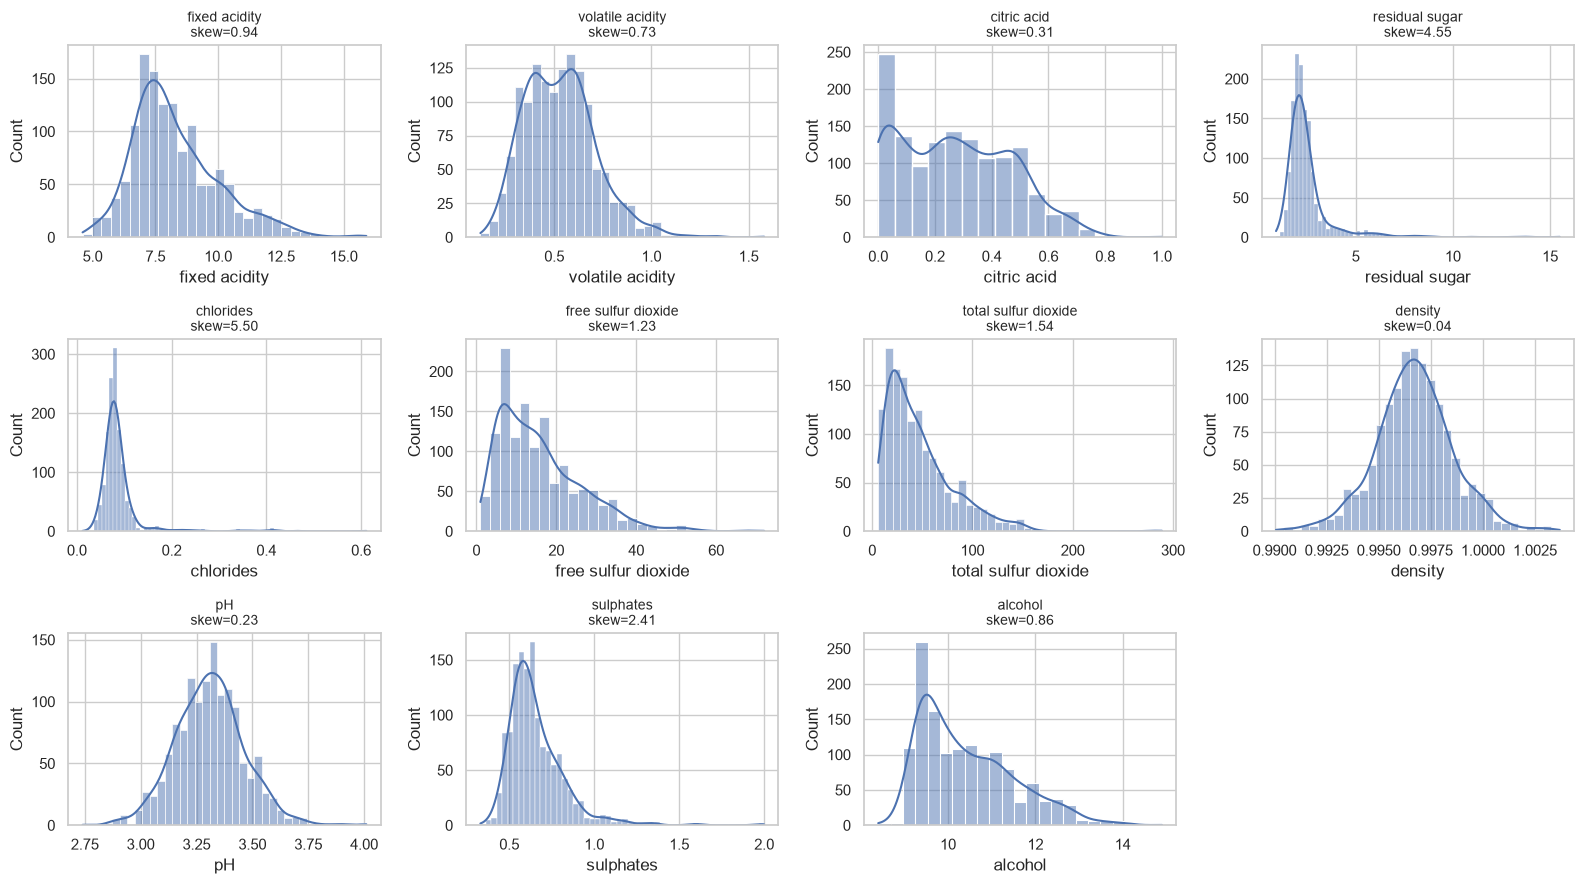

,skewness,kurtosis
chlorides,5.50,38.62
residual sugar,4.55,29.36
sulphates,2.41,11.10
total sulfur dioxide,1.54,4.04
free sulfur dioxide,1.23,1.89
fixed acidity,0.94,1.05
alcohol,0.86,0.16
volatile acidity,0.73,1.25
citric acid,0.31,-0.79
pH,0.23,0.88


In [93]:
def grid(n, ncols=4, h=3):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for a in axes[n:]: a.axis("off")
    return fig, axes

fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    sns.histplot(df[c], kde=True, ax=a, color="#4C72B0")
    a.set_title(f"{c}\nskew={df[c].skew():.2f}", fontsize=10)
plt.tight_layout(); plt.show()

skew_tab = df[raw_features].skew().sort_values(ascending=False).to_frame("skewness")
skew_tab["kurtosis"] = df[raw_features].kurt()
display(skew_tab.round(2))

**Interpretación.** Variables con asimetría |skew| > 1 (típicamente `residual sugar`, `chlorides`, `sulphates`,
`total sulfur dioxide`) tienen colas largas a la derecha. En regresión logística no se exige normalidad de las predictoras,
pero las colas pesadas hacen que unos pocos puntos dominen el gradiente y los coeficientes; una transformación logarítmica lo mitiga
(sección 5).

### 3.2 Valores atípicos (boxplots)

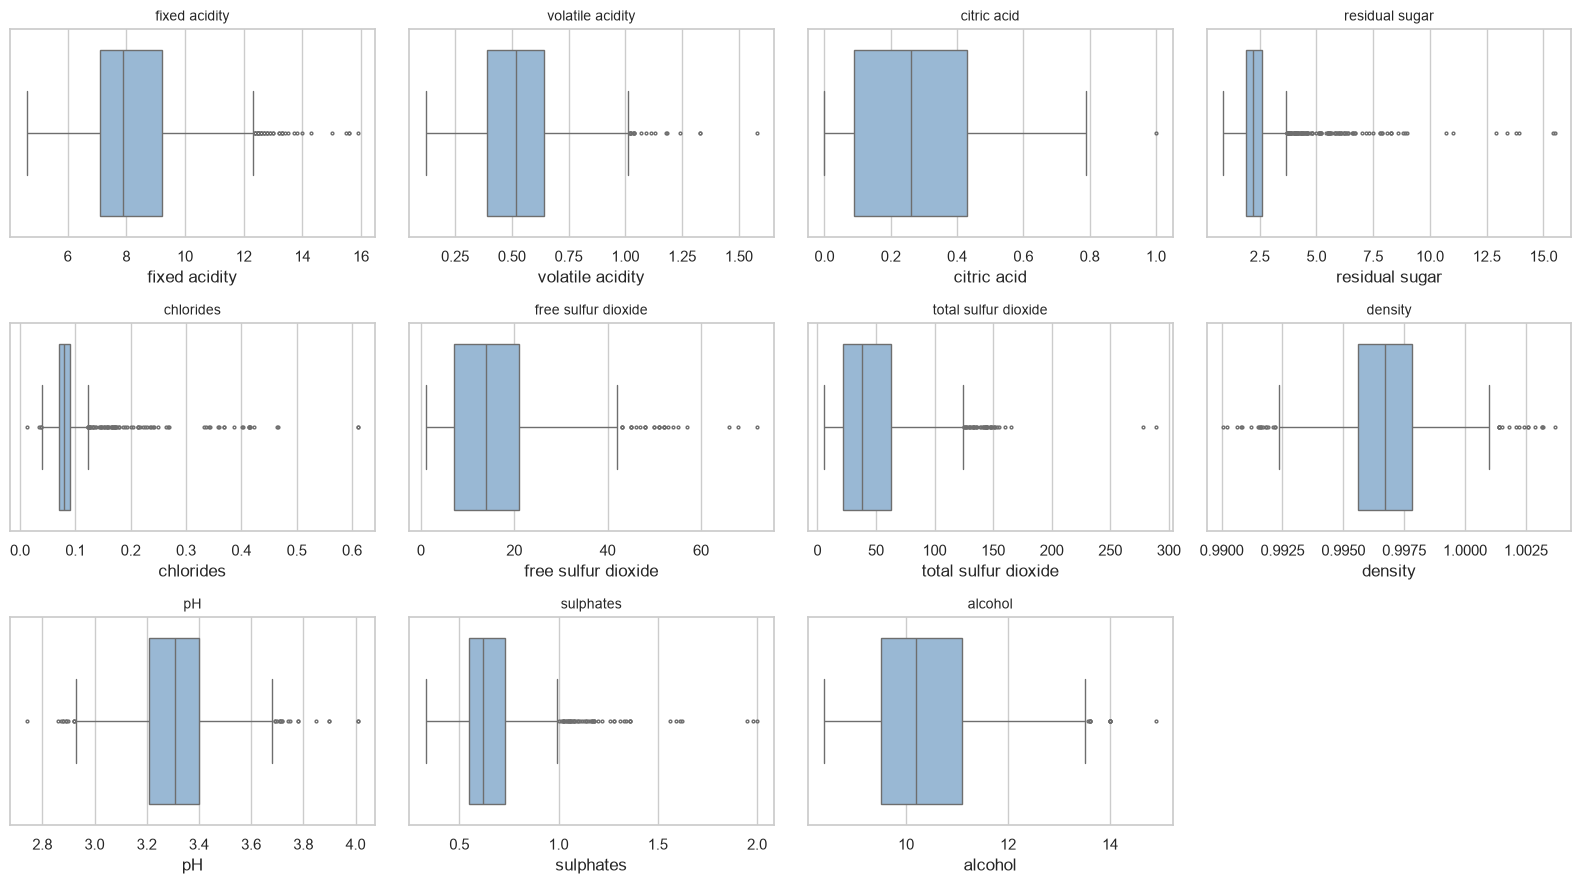

,n_outliers (regla IQR),%
residual sugar,126,9.3
chlorides,87,6.4
sulphates,55,4.0
total sulfur dioxide,45,3.3
fixed acidity,41,3.0
density,35,2.6
pH,28,2.1
free sulfur dioxide,26,1.9
volatile acidity,19,1.4
alcohol,12,0.9


In [94]:
fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    sns.boxplot(x=df[c], ax=a, color="#8FB8DE", fliersize=2)
    a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

q1, q3 = df[raw_features].quantile(.25), df[raw_features].quantile(.75)
iqr = q3 - q1
out = ((df[raw_features] < q1 - 1.5 * iqr) | (df[raw_features] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({"n_outliers (regla IQR)": out, "%": (out / len(df) * 100).round(1)}).sort_values("%", ascending=False))

**Interpretación.** Los puntos fuera de 1.5·IQR son frecuentes en las variables asimétricas. No se eliminan: en este dominio
son vinos reales (no errores de medición evidentes) y eliminarlos reduciría muestra. En su lugar se atenúan con `log1p`
y con estandarización.

### 3.3 Relación de cada variable con el target

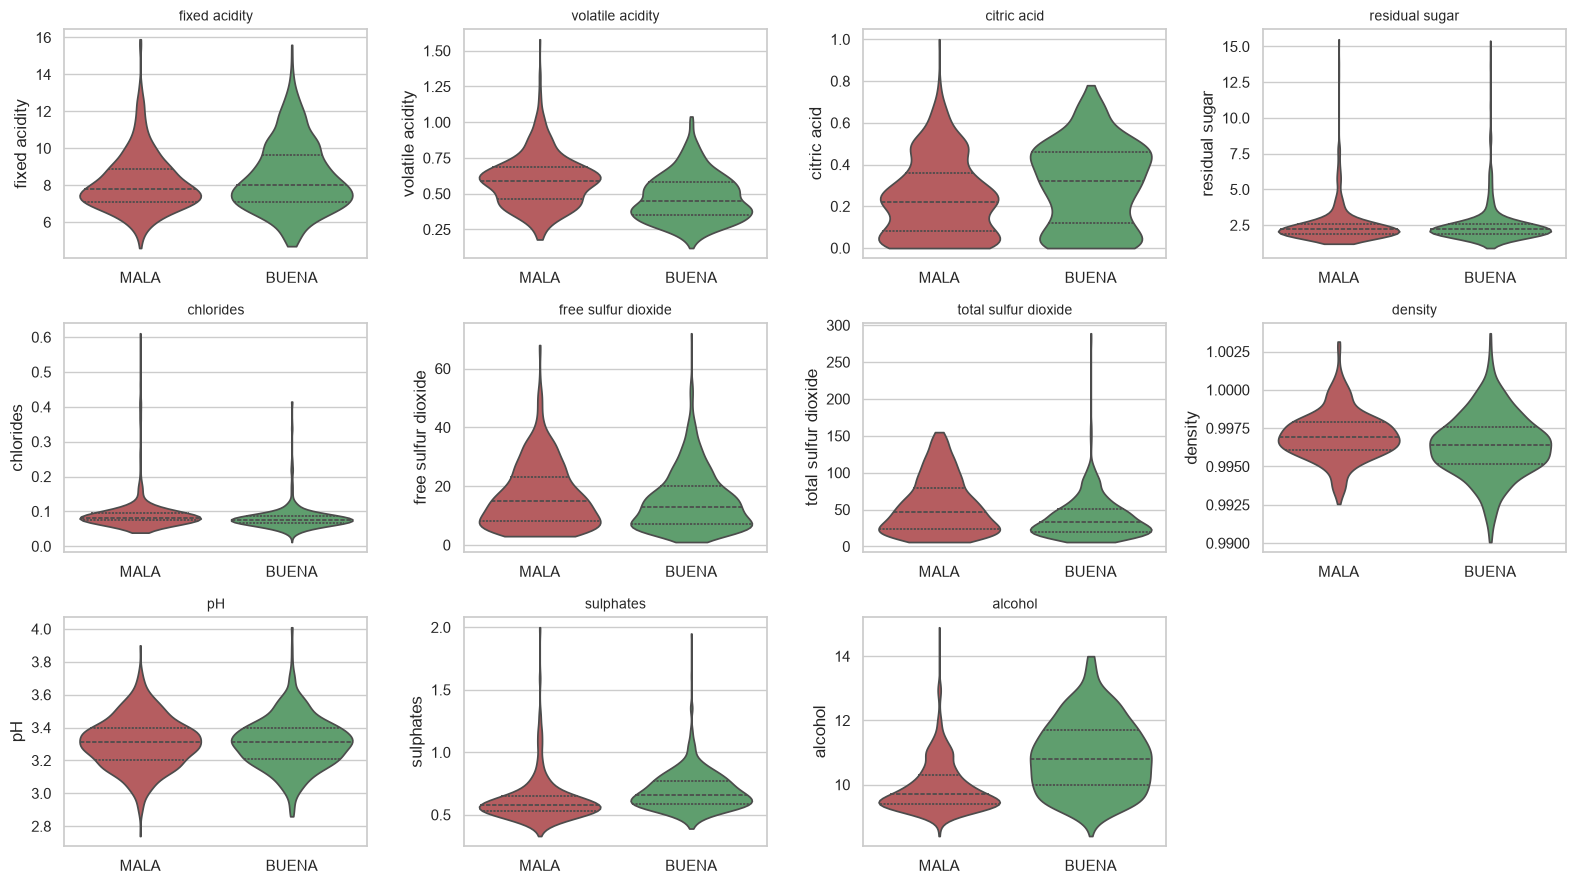

In [95]:
fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    sns.violinplot(data=df, x="target", y=c, ax=a, palette=["#C44E52", "#55A868"], inner="quartile", cut=0)
    a.set_xticklabels(["MALA", "BUENA"]); a.set_xlabel(""); a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

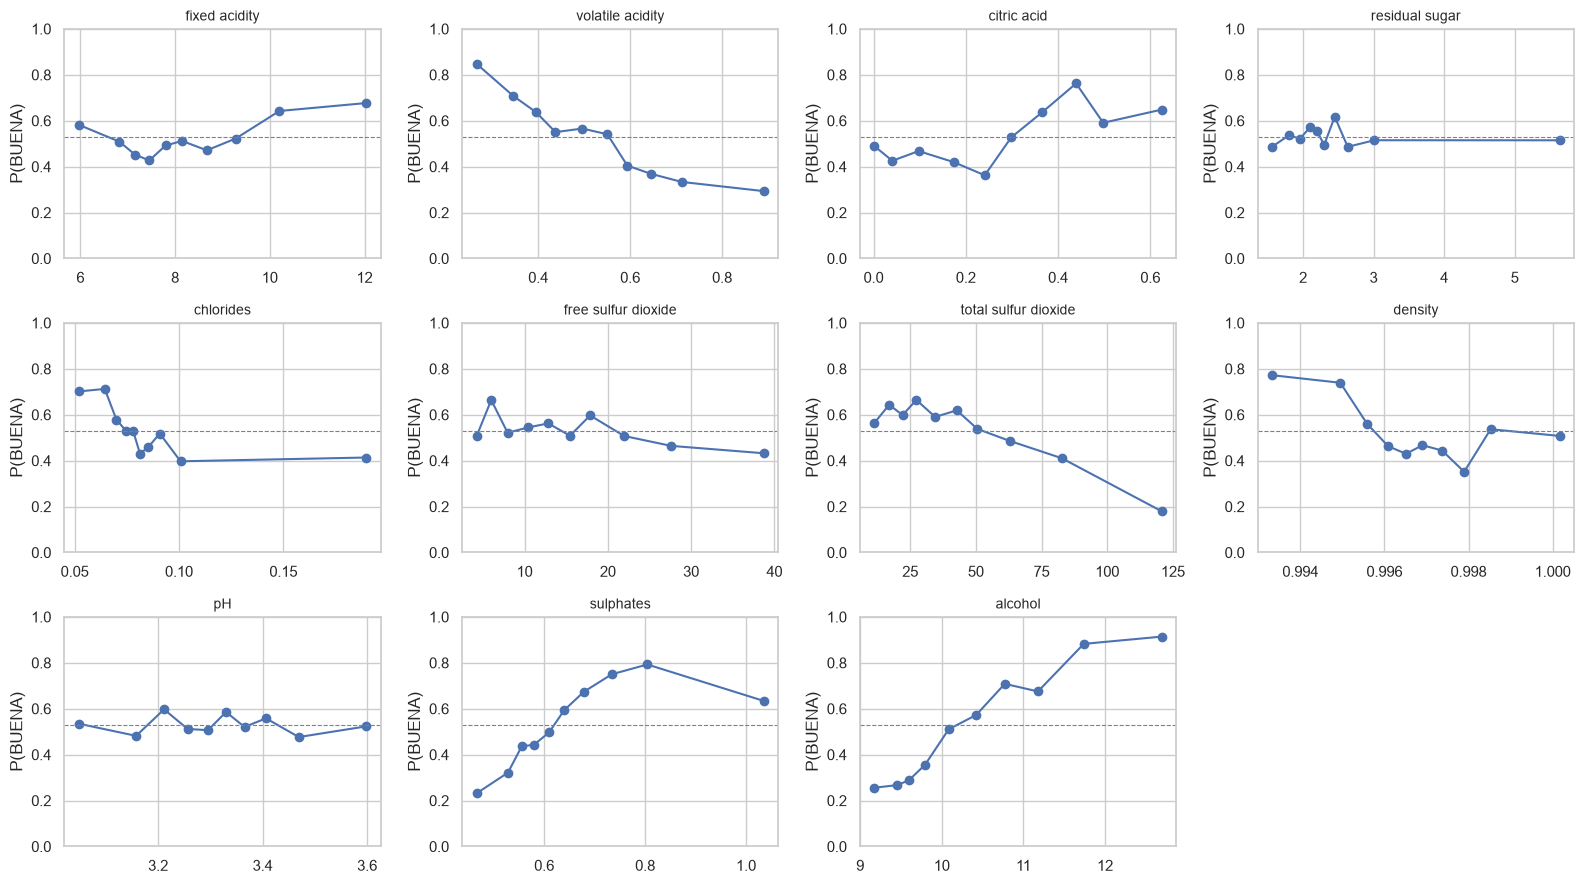

In [96]:
# Dispersión vs target binario: probabilidad empírica de BUENA por deciles de cada variable
# (si la relación es monótona, el modelo logístico es apropiado)
fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    b = pd.qcut(df[c], 10, duplicates="drop")
    g = df.groupby(b, observed=True).agg(x=(c, "mean"), p=("target", "mean"))
    a.plot(g.x, g.p, "o-"); a.set_ylim(0, 1); a.axhline(df.target.mean(), ls="--", c="gray", lw=.8)
    a.set_title(c, fontsize=10); a.set_ylabel("P(BUENA)")
plt.tight_layout(); plt.show()

**Interpretación.** Las curvas monótonas y con pendiente marcada (p. ej. `alcohol` creciente, `volatile acidity` decreciente)
indican predictores informativos con relación aproximadamente logit-lineal. Curvas planas sobre la línea punteada
(media global) indican poca señal individual (p. ej. `residual sugar`, `free sulfur dioxide`, `pH` suelen ser débiles).

### 3.4 Correlaciones

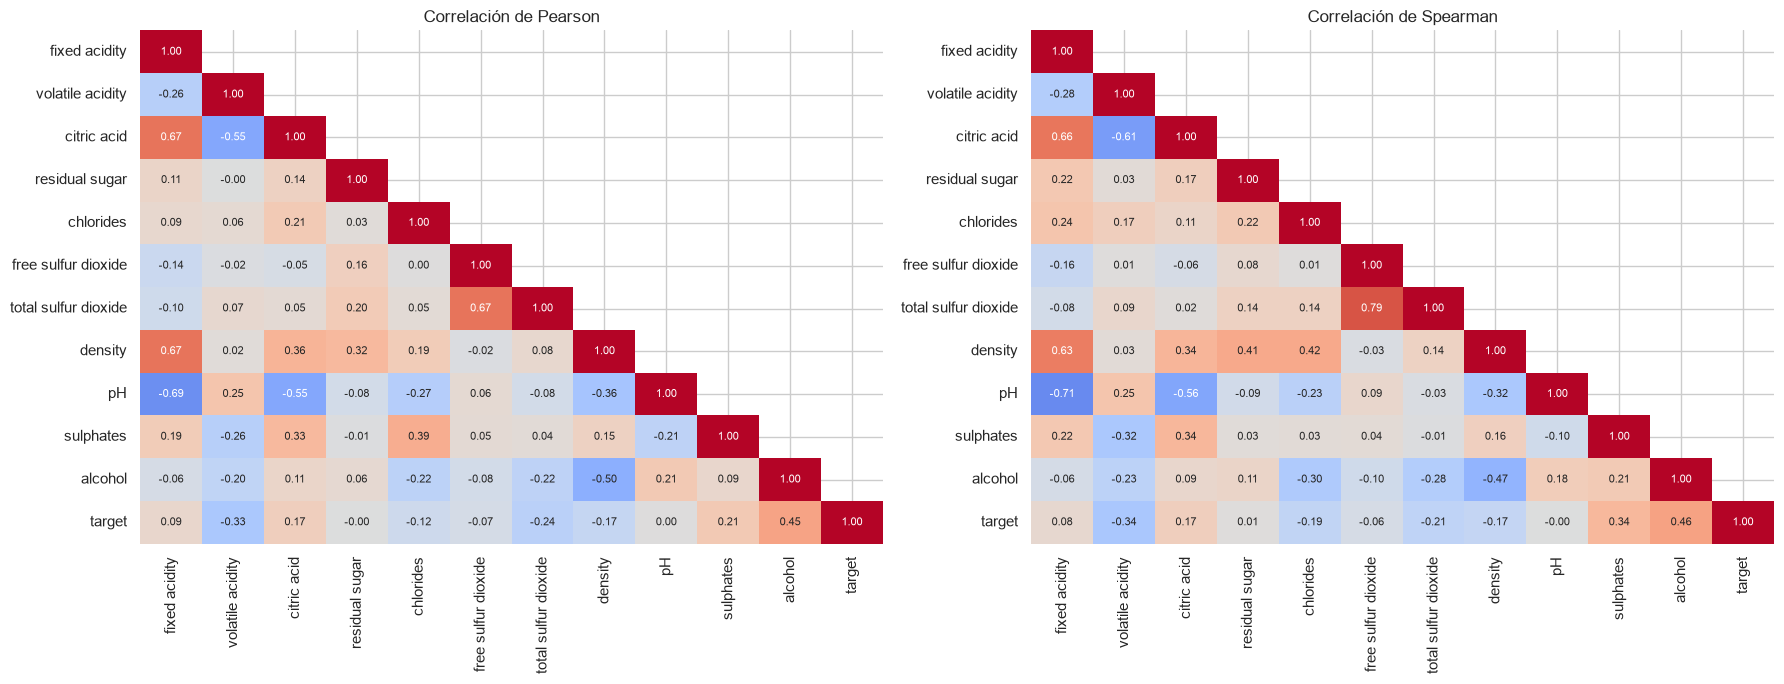

Correlación con el target (Pearson = punto-biserial):


,r
alcohol,0.446
volatile acidity,-0.327
total sulfur dioxide,-0.235
sulphates,0.211
density,-0.169
citric acid,0.168
chlorides,-0.115
fixed acidity,0.092
free sulfur dioxide,-0.069
pH,0.005


In [97]:
corr_p = df[raw_features + ["target"]].corr(method="pearson")
corr_s = df[raw_features + ["target"]].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, m, t in zip(ax, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                mask=np.triu(np.ones_like(m, dtype=bool), 1), ax=a, annot_kws={"size": 8}, cbar=False)
    a.set_title(f"Correlación de {t}")
plt.tight_layout(); plt.show()

print("Correlación con el target (Pearson = punto-biserial):")
display(corr_p["target"].drop("target").sort_values(key=abs, ascending=False).to_frame("r").round(3))

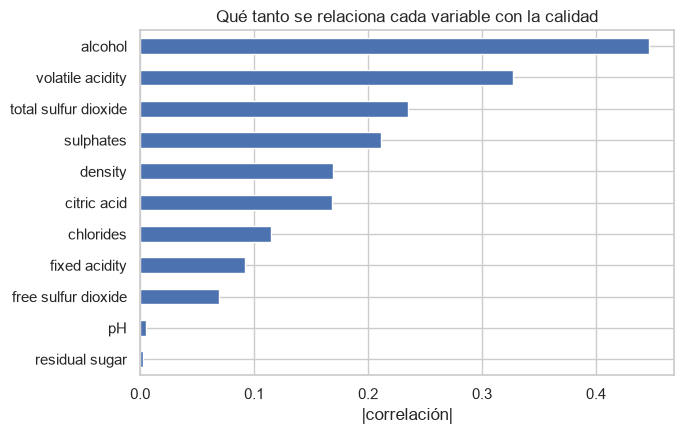

In [112]:
corr_target = corr_p["target"].drop("target").abs().sort_values()

corr_target.plot.barh(figsize=(7, 4.5), color="#4C72B0")
plt.xlabel("|correlación|")
plt.title("Qué tanto se relaciona cada variable con la calidad")
plt.tight_layout()
plt.show()

In [99]:
pairs = corr_p.loc[raw_features, raw_features].abs().where(np.triu(np.ones((len(raw_features),)*2), 1).astype(bool)).stack()
print("Pares de predictoras más correlacionados (|r|):")
display(pairs.sort_values(ascending=False).head(6).round(3).to_frame("|r|"))

Pares de predictoras más correlacionados (|r|):


|r|
fixed acidity       pH                    0.687
                    density               0.670
                    citric acid           0.667
free sulfur dioxide total sulfur dioxide  0.667
volatile acidity    citric acid           0.551
citric acid         pH                    0.550

**Interpretación.** Dos hallazgos que guían la selección:

* **Relevancia:** las variables con mayor |r| con el target (típicamente `alcohol`, `volatile acidity`, `sulphates`, `citric acid`)
  son candidatas naturales.
* **Redundancia:** pares como `fixed acidity`–`pH`, `fixed acidity`–`density`, `fixed acidity`–`citric acid` y
  `free`–`total sulfur dioxide` están muy correlacionados. Si dejo las dos, estoy repitiendo casi la misma información.
  En la sección 6 me quedo solo con una de cada par.

## 4. Partición estratificada: train / validación / test

**Técnica elegida: *stratified hold-out* 70 / 15 / 15** (dos divisiones sucesivas con `stratify=target`).

* Estratificar mantiene la proporción BUENA/MALA idéntica en los tres conjuntos, de modo que las métricas sean comparables y la
  validación/test no queden con muy pocos positivos.
* Se prefiere hold-out a k-fold porque se requiere un conjunto de validación fijo para *early stopping* y ajuste de hiperparámetros en PyTorch,
  y un test intacto al final.
* **Toda decisión de preprocesamiento y selección se toma solo con train.**

In [100]:
X_raw, y = df[raw_features], df["target"]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_raw, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(pd.DataFrame({
    "n": [len(y_tr), len(y_va), len(y_te)],
    "% BUENA": [y_tr.mean(), y_va.mean(), y_te.mean()],
}, index=["train", "val", "test"]).round(3))

         n  % BUENA
train  951    0.529
val    204    0.529
test   204    0.529


## 5. Variables nuevas

En el EDA se vio que algunas columnas tienen una cola larga a la derecha. A esas se les aplica logaritmo para que unos pocos vinos con valores muy altos no pesen tanto. El sesgo se ve solo en train.

También armamos una columna nueva, `so2_ratio`: qué parte del azufre total libre. En la sección 6, si esta columna y las de azufre dicen lo mismo, nos quedamos con la mejor.

In [101]:
skewed = X_tr.skew()[X_tr.skew().abs() > 1].index.tolist()
print("Log aplicado debido al sesgo:", skewed)

def agregar_variables(X):
    out = X.copy()
    out["so2_ratio"] = out["free sulfur dioxide"] / out["total sulfur dioxide"].replace(0, np.nan)
    out["so2_ratio"] = out["so2_ratio"].fillna(0)
    for c in skewed:
        out[c] = np.log1p(out[c])
    return out

F_tr = agregar_variables(X_tr)
F_va = agregar_variables(X_va)
F_te = agregar_variables(X_te)
print("Columnas que quedan:", F_tr.columns.tolist())

Log aplicado debido al sesgo: ['fixed acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates']
Columnas que quedan: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'so2_ratio']


## 6. Elegir las 6 mejores características

La selección se realiza mediante dos criterios, utilizando únicamente el conjunto de entrenamiento:

- Se calcula la correlación entre cada variable y el objetivo. Las variables con mayor valor absoluto de correlación se consideran más informativas.
- Para reducir la redundancia, si dos variables presentan una correlación superior a 0.7, se conserva la que muestra mayor relación con el objetivo.

Finalmente, se seleccionan las seis variables más informativas que cumplen estos criterios.

In [102]:
# Recorremos de la más relacionada a la menos. Si una se parece mucho a otra ya elegída, la saltamos.
UMBRAL = 0.70
corr_x = F_tr.corr().abs()
selected = []
quito_alguna = False
for c in corr_y.abs().sort_values(ascending=False).index:
    se_parece = False
    for s in selected:
        if corr_x.loc[c, s] > UMBRAL:
            print(f"Quitamos '{c}' porque se parece a '{s}' (correlación {corr_x.loc[c, s]:.2f})")
            se_parece = True
            quito_alguna = True
            break
    if se_parece:
        continue
    selected.append(c)
    if len(selected) == MAX_FEATURES:
        break

if not quito_alguna:
    print("Ninguna de las primeras se parecía tanto a otra ya elegida.")

print("\nLas 6 características:", selected)
display(corr_y[selected].round(3).to_frame("correlación con target"))

Ninguna de las primeras se parecía tanto a otra ya elegida.

Las 6 características: ['alcohol', 'volatile acidity', 'sulphates', 'so2_ratio', 'total sulfur dioxide', 'density']


,correlación con target
alcohol,0.454
volatile acidity,-0.295
sulphates,0.235
so2_ratio,0.233
total sulfur dioxide,-0.209
density,-0.178


Con esto entendemos los siguiente:
Cuando suben:
- alcohol
- sulphates
- so2_ratio

El vino tiende a ser **BUENO**

Cuando suben:
- volatile acidity
- total sulfur dioxide
- density

El vino tiende a ser **MALO**

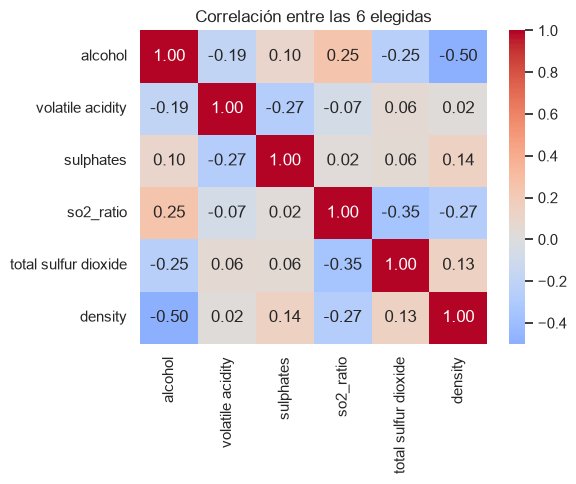

In [103]:
# Revisamos que entre las 6 elegidas no quede un par que diga lo mismo (Muy correlacionado)
plt.figure(figsize=(6, 5))
sns.heatmap(F_tr[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlación entre las 6 elegidas")
plt.tight_layout()
plt.show()

**Interpretación**. Se seleccionan seis variables con mayor relación con la calidad del vino y con menor redundancia entre sí. En general, se espera que valores más altos de alcohol y sulfatos se asocien con vinos de mejor calidad, mientras que una mayor acidez volátil tiende a relacionarse con vinos de menor calidad. Las variables no seleccionadas, o aquellas con alta similitud con estas características, muestran una relación débil o redundante con la variable objetivo.

## 7. Estandarizar y guardar

Calculamos la media y la desviación solo con train, con eso escalamos validación y test. Así las 6 variables quedan en la misma escala antes de entrenar.

> En caso de no mostrar mejoria se puede omitir este paso para ver comportamiento del modelo



In [104]:
final_sc = StandardScaler().fit(F_tr[selected])

def escalar(F):
    return final_sc.transform(F[selected]).astype("float32")

A_tr, A_va, A_te = escalar(F_tr), escalar(F_va), escalar(F_te)

np.savez("wine_splits.npz",
         X_train=A_tr, y_train=y_tr.values.astype("float32"),
         X_val=A_va,   y_val=y_va.values.astype("float32"),
         X_test=A_te,  y_test=y_te.values.astype("float32"),
         features=np.array(selected))
print("Guardado wine_splits.npz | shapes:", A_tr.shape, A_va.shape, A_te.shape)
print("Media train (cerca de 0):", A_tr.mean(0).round(3))
print("Desv. train (cerca de 1):", A_tr.std(0).round(3))

# Después, en PyTorch:
#   import torch; d = np.load("wine_splits.npz")
#   X_train = torch.tensor(d["X_train"]); y_train = torch.tensor(d["y_train"]).unsqueeze(1)

Guardado wine_splits.npz | shapes: (951, 6) (204, 6) (204, 6)
Media train (cerca de 0): [ 0.  0. -0. -0. -0.  0.]
Desv. train (cerca de 1): [1. 1. 1. 1. 1. 1.]


## Siguientes pasos

Con `wine_splits.npz` ya se puede entrenar la regresión logística en PyTorch: una combinación lineal de las 6 variables, pasada por una sigmoide, con pérdida BCE (`nn.BCEWithLogitsLoss`). Conviene usar validación para decidir cuándo parar, y al final reportar en test accuracy, precision, recall, F1, ROC-AUC y la matriz de confusión.